# 4. Modeling: Pelatihan & Komparasi Model Klasifikasi Kerapian Alas Kaki

Tahap **Modeling** membandingkan **8 kandidat model klasifikasi** menggunakan validasi silang berbasis kelompok (**5-Fold `StratifiedGroupKFold`**) pada data pengembangan (**120 citra unik** dari 6 kelompok):

1. **Prosedur Anti-Kebocoran (*Leakage-Free Pipeline*):**
   * Seluruh foto dari satu kelompok tidak pernah terpecah antara *train fold* dan *validation fold*.
   * `StandardScaler` dihitung ulang murni dari masing-masing *train fold*.
   * Augmentasi pencerminan horizontal (*horizontal flip*) hanya digabungkan ke dalam **train fold** ($X_{\text{train}} \cup X_{\text{flip}}$), dan **tidak pernah** dimasukkan ke *validation fold* maupun *test set*.
2. **Kandidat Model yang Dibandingkan:**
   * `LightGBM` (Gradient Boosted Trees terregularisasi: `max_depth=3, num_leaves=7`).
   * `MLP_Ensemble` (*Soft-Voting* 3 Neural Network MLP multi-seed dengan regularisasi L2 `alpha=1.0`).
   * `HybridVoting` (*Soft-Voting* gabungan `MLP + SVC + LogisticRegression + LightGBM`).
   * `LogisticRegression` (`C=0.5`, pembobotan kelas seimbang).
   * `SVC` (*Support Vector Classifier* kernel RBF, dikalibrasi probabilitasnya dengan `CalibratedClassifierCV`).
   * `ExtraTrees`, `RandomForest`, dan `GradientBoosting`.
3. **Kriteria Pemilihan:** Model terbaik dipilih secara otomatis berdasarkan rata-rata **Validation Macro-F1** tertinggi, kemudian dilatih ulang pada seluruh 120 citra pengembangan (+120 augmentasi horizontal = 240 sampel latih).


In [1]:
import sys
from pathlib import Path
import pandas as pd


def find_project_dir():
    for base in (Path.cwd(), *Path.cwd().parents):
        for candidate in (base, base / "src" / "10-project_citra"):
            if (candidate / "3-data_preparation").is_dir() and (candidate / "6-deployment").is_dir():
                return candidate.resolve()
    raise FileNotFoundError("Folder proyek 10-project_citra tidak ditemukan dari direktori kerja.")


PROJECT_DIR = find_project_dir()
sys.path.insert(0, str(PROJECT_DIR))
DATA_PROCESSED = PROJECT_DIR / "3-data_preparation" / "data" / "processed"
manifest = pd.read_csv(DATA_PROCESSED / "dataset_manifest.csv")
training_df = manifest.loc[
    (manifest["split"] != "test") & manifest["include_in_model"]
].reset_index(drop=True)

print(
    f"Data pengembangan: {len(training_df)} citra unik dari "
    f"{training_df['kelompok'].nunique()} kelompok "
    f"({sorted(training_df['kelompok'].unique())})."
)


Data pengembangan: 120 citra unik dari 6 kelompok (['kelompok 1', 'kelompok 3', 'kelompok 4', 'kelompok 5', 'kelompok 6', 'kelompok 7']).


---
## 4.1 Pelatihan & Komparasi 8 Model pada 5-Fold *StratifiedGroupKFold*

Menjalankan fungsi `train_model(manifest)` untuk mengevaluasi seluruh kandidat model dan mengurutkan hasilnya berdasarkan `validation_macro_f1`.


In [2]:
from pipeline import train_model

training_result = train_model(manifest)
best_model_name = training_result["model_name"]
best_model = training_result["model"]
df_res = pd.DataFrame(training_result["results"]).sort_values(
    "validation_macro_f1", ascending=False
).reset_index(drop=True)

print("\n=== Tabel Perbandingan Performa Model (5-Fold StratifiedGroupKFold) ===")
display(df_res.round(4))
print(f"\nModel terpilih berdasarkan Validation Macro-F1 tertinggi: {best_model_name}")


Model terpilih: LightGBM (macro-F1 validasi 0.716)
Model akhir dilatih pada 120 citra unik (+120 augmentasi horizontal = 240 sampel).

=== Tabel Perbandingan Performa Model (5-Fold StratifiedGroupKFold) ===


,model,validation_accuracy_mean,validation_accuracy_std,validation_macro_f1,validation_macro_f1_std,validation_precision_macro_mean,validation_recall_macro_mean
0,LightGBM,0.7493,0.1176,0.7157,0.1403,0.7315,0.7488
1,MLP_Ensemble,0.7391,0.1104,0.6788,0.1672,0.7036,0.6989
2,LogisticRegression,0.7279,0.1159,0.6717,0.1700,0.7239,0.6973
3,HybridVoting,0.7266,0.1251,0.6661,0.1732,0.6855,0.6832
4,ExtraTrees,0.6876,0.1179,0.6301,0.1626,0.6394,0.6494
5,SVC,0.6612,0.0921,0.6036,0.1510,0.6551,0.6426
6,GradientBoosting,0.6589,0.0652,0.6027,0.1333,0.6422,0.6376
7,RandomForest,0.6370,0.0826,0.5846,0.1368,0.6382,0.6191



Model terpilih berdasarkan Validation Macro-F1 tertinggi: LightGBM


---
## 4.2 Visualisasi Perbandingan Performa Model & Penyimpanan Artefak Terbaik

Visualisasi rata-rata Akurasi Validasi dan Macro-F1 antar kandidat model, serta verifikasi penyimpanan artefak ke direktori `4-modeling/models/` dan `6-deployment/`.


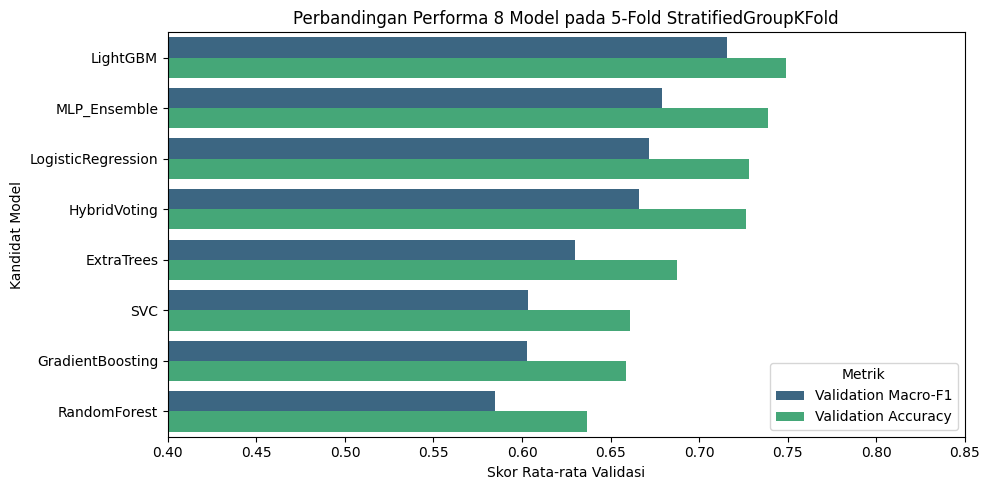

Model LightGBM, scaler, dan daftar 65 fitur telah tersimpan pada direktori 4-modeling/models/ dan 6-deployment/.


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(10, 5))
df_melt = df_res.melt(
    id_vars="model",
    value_vars=["validation_macro_f1", "validation_accuracy_mean"],
    var_name="Metrik",
    value_name="Skor",
)
df_melt["Metrik"] = df_melt["Metrik"].replace({
    "validation_macro_f1": "Validation Macro-F1",
    "validation_accuracy_mean": "Validation Accuracy",
})
sns.barplot(data=df_melt, y="model", x="Skor", hue="Metrik", palette="viridis", ax=ax)
ax.set_xlim(0.4, 0.85)
ax.set_title("Perbandingan Performa 8 Model pada 5-Fold StratifiedGroupKFold", fontsize=12)
ax.set_xlabel("Skor Rata-rata Validasi")
ax.set_ylabel("Kandidat Model")
plt.tight_layout()
plt.savefig(PROJECT_DIR / "4-modeling" / "models" / "model_comparison_chart.png", dpi=200)
plt.show()

print(
    f"Model {best_model_name}, scaler, dan daftar 65 fitur telah tersimpan "
    "pada direktori 4-modeling/models/ dan 6-deployment/."
)
